In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

In [2]:
df=pd.read_csv('Travel.csv')

In [3]:
df.head(10)

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0
5,200005,0,32.0,Company Invited,1,8.0,Salaried,Male,3,3.0,Basic,3.0,Single,1.0,0,5,1,1.0,Executive,18068.0
6,200006,0,59.0,Self Enquiry,1,9.0,Small Business,Female,2,2.0,Basic,5.0,Divorced,5.0,1,2,1,1.0,Executive,17670.0
7,200007,0,30.0,Self Enquiry,1,30.0,Salaried,Male,3,3.0,Basic,3.0,Married,2.0,0,2,0,1.0,Executive,17693.0
8,200008,0,38.0,Company Invited,1,29.0,Salaried,Male,2,4.0,Standard,3.0,Unmarried,1.0,0,3,0,0.0,Senior Manager,24526.0
9,200009,0,36.0,Self Enquiry,1,33.0,Small Business,Male,3,3.0,Deluxe,3.0,Divorced,7.0,0,3,1,0.0,Manager,20237.0


In [4]:
##check for null values
df.isnull().sum()

CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

In [5]:
print(df['Age'].unique()) ##median imputation
print(df['TypeofContact'].unique()) ##categorical feature ##mode imputation
print(df['DurationOfPitch'].unique()) #median imputation
print(df['NumberOfFollowups'].unique()) #mode
print(df['PreferredPropertyStar'].unique()) #mode
print(df['NumberOfTrips'].unique()) #mode
print(df['NumberOfChildrenVisiting'].unique()) #mode
print(df['MonthlyIncome'].unique()) #median 

[41. 49. 37. 33. nan 32. 59. 30. 38. 36. 35. 31. 34. 28. 29. 22. 53. 21.
 42. 44. 46. 39. 24. 43. 50. 27. 26. 48. 55. 45. 56. 23. 51. 40. 54. 58.
 20. 25. 19. 57. 52. 47. 18. 60. 61.]
<ArrowStringArray>
['Self Enquiry', 'Company Invited', nan]
Length: 3, dtype: str
[  6.  14.   8.   9.  30.  29.  33.  22.  21.  32.  25.  27.  11.  17.
  15.  13.  12.  16.  10.  31.  18.  nan  24.  35.  28.  20.  26.  34.
  23.   5.  19. 126.   7.  36. 127.]
[ 3.  4.  2.  5. nan  1.  6.]
[ 3.  4.  5. nan]
[ 1.  2.  7.  5.  6.  3.  4. 19. 21.  8. nan 20. 22.]
[ 0.  2.  1. nan  3.]
[20993. 20130. 17090. ... 22097. 22995. 21471.]


In [6]:
##extracting all features which is having null values
feature_with_na=[feature for feature in df.columns if df[feature].isnull().sum()>=1]
print(feature_with_na)
for feature in feature_with_na:
    print(feature,np.round(df[feature].isnull().mean()*100,5),'% Null values')

['Age', 'TypeofContact', 'DurationOfPitch', 'NumberOfFollowups', 'PreferredPropertyStar', 'NumberOfTrips', 'NumberOfChildrenVisiting', 'MonthlyIncome']
Age 4.62357 % Null values
TypeofContact 0.51146 % Null values
DurationOfPitch 5.13502 % Null values
NumberOfFollowups 0.92062 % Null values
PreferredPropertyStar 0.53191 % Null values
NumberOfTrips 2.86416 % Null values
NumberOfChildrenVisiting 1.35025 % Null values
MonthlyIncome 4.76678 % Null values


In [7]:
##missing value imputaion
#Age
df.Age=df.Age.fillna(df.Age.median(),inplace=True)
#TypeofContact
df.TypeofContact=df.TypeofContact.fillna(df.TypeofContact.mode()[0],inplace=True)
#Duration of pitch
df.DurationOfPitch=df.DurationOfPitch.fillna(df.DurationOfPitch.median(),inplace=True)
#number of followups
df.NumberOfFollowups=df.NumberOfFollowups.fillna(df.NumberOfFollowups.mode()[0],inplace=True)
##PreferredPropertystar
df.PreferredPropertyStar=df.PreferredPropertyStar.fillna(df.PreferredPropertyStar.mode()[0],inplace=True)
##number of trips
df.NumberOfTrips=df.NumberOfTrips.fillna(df.NumberOfTrips.mode()[0],inplace=True)
##number of children visiting
df.NumberOfChildrenVisiting=df.NumberOfChildrenVisiting.fillna(df.NumberOfChildrenVisiting.mode()[0],inplace=True)
##Monthly income
df.MonthlyIncome=df.MonthlyIncome.fillna(df.MonthlyIncome.median(),inplace=True)

In [8]:
df.isnull().sum()

CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64

In [9]:
##create one TotalVisiting feature to add two features together
df['TotalVisiting']=df['NumberOfChildrenVisiting']+df['NumberOfPersonVisiting']

##now drop the both features which has been added recently
df.drop(columns=['NumberOfChildrenVisiting','NumberOfPersonVisiting'],inplace=True)

In [10]:
df.head(10)

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,Designation,MonthlyIncome,TotalVisiting
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3.0,Deluxe,3.0,Single,1.0,1,2,1,Manager,20993.0,3.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,Manager,20130.0,5.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,4.0,Basic,3.0,Single,7.0,1,3,0,Executive,17090.0,3.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,3.0,Basic,3.0,Divorced,2.0,1,5,1,Executive,17909.0,3.0
4,200004,0,36.0,Self Enquiry,1,8.0,Small Business,Male,3.0,Basic,4.0,Divorced,1.0,0,5,1,Executive,18468.0,2.0
5,200005,0,32.0,Company Invited,1,8.0,Salaried,Male,3.0,Basic,3.0,Single,1.0,0,5,1,Executive,18068.0,4.0
6,200006,0,59.0,Self Enquiry,1,9.0,Small Business,Female,2.0,Basic,5.0,Divorced,5.0,1,2,1,Executive,17670.0,3.0
7,200007,0,30.0,Self Enquiry,1,30.0,Salaried,Male,3.0,Basic,3.0,Married,2.0,0,2,0,Executive,17693.0,4.0
8,200008,0,38.0,Company Invited,1,29.0,Salaried,Male,4.0,Standard,3.0,Unmarried,1.0,0,3,0,Senior Manager,24526.0,2.0
9,200009,0,36.0,Self Enquiry,1,33.0,Small Business,Male,3.0,Deluxe,3.0,Divorced,7.0,0,3,1,Manager,20237.0,3.0


In [11]:
##Extracting Features
##extract numerical features
numerical_features=[feature for feature in df.columns if df[feature].dtypes!='str']
print('Number of numerical features:',len(numerical_features))
print(numerical_features)

Number of numerical features: 13
['CustomerID', 'ProdTaken', 'Age', 'CityTier', 'DurationOfPitch', 'NumberOfFollowups', 'PreferredPropertyStar', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar', 'MonthlyIncome', 'TotalVisiting']


In [12]:
##extractig categorical features
categorical_features=[feature for feature in df.columns if df[feature].dtypes=='str']
print("Number of categorical Features are:",len(categorical_features))
print(categorical_features)

Number of categorical Features are: 6
['TypeofContact', 'Occupation', 'Gender', 'ProductPitched', 'MaritalStatus', 'Designation']


In [13]:
##Extracting discrete features from numerical features
discrete_features=[feature for feature in numerical_features if len(df[feature].unique())<=25]
print("Number of discrete Features are:",len(discrete_features))
print(discrete_features)

Number of discrete Features are: 9
['ProdTaken', 'CityTier', 'NumberOfFollowups', 'PreferredPropertyStar', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar', 'TotalVisiting']


In [14]:
##extracting continous features from numerical features
continous_features=[feature for feature in numerical_features if len(df[feature].unique())>=25]
print("Number of continous features are:",len(continous_features))
print(continous_features)

Number of continous features are: 4
['CustomerID', 'Age', 'DurationOfPitch', 'MonthlyIncome']


In [15]:
##drop customerid feature
df.drop(columns='CustomerID',inplace=True)

In [16]:
##independent & dependent features
x=df.drop(columns='ProdTaken')
y=df['ProdTaken']

In [17]:
x.head()

,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,Designation,MonthlyIncome,TotalVisiting
0,41.0,Self Enquiry,3,6.0,Salaried,Female,3.0,Deluxe,3.0,Single,1.0,1,2,1,Manager,20993.0,3.0
1,49.0,Company Invited,1,14.0,Salaried,Male,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,Manager,20130.0,5.0
2,37.0,Self Enquiry,1,8.0,Free Lancer,Male,4.0,Basic,3.0,Single,7.0,1,3,0,Executive,17090.0,3.0
3,33.0,Company Invited,1,9.0,Salaried,Female,3.0,Basic,3.0,Divorced,2.0,1,5,1,Executive,17909.0,3.0
4,36.0,Self Enquiry,1,8.0,Small Business,Male,3.0,Basic,4.0,Divorced,1.0,0,5,1,Executive,18468.0,2.0


In [18]:
##Train_Test Split
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42)

In [19]:
##create transformers for feature encoding and scaling
num_features=x.select_dtypes(exclude=str).columns
cat_features=x.select_dtypes(include=str).columns

##import numerical transformer
from sklearn.preprocessing import StandardScaler
#import categorical transformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

##create transformers
num_transformer=StandardScaler()
cat_transformer=OneHotEncoder(drop='first')

preprocessor=ColumnTransformer(
    [
        ('StandardScaler',num_transformer,num_features),
        ('OneHotEncoder',cat_transformer,cat_features)
    ]
)



In [20]:
x_train=preprocessor.fit_transform(x_train)
x_test=preprocessor.transform(x_test)

In [21]:
pd.DataFrame(x_train)

,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,-0.157926,-0.721400,-1.020350,1.284279,-0.725271,-0.111835,-0.632399,0.679690,0.782966,-0.382245,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
1,0.508072,-0.721400,0.690023,0.282777,-0.725271,1.517765,-0.632399,0.679690,0.782966,-0.459799,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1.396069,-0.721400,-1.020350,0.282777,1.771041,0.431365,-0.632399,0.679690,0.782966,-0.245196,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0.064073,-0.721400,-1.020350,1.284279,-0.725271,-0.111835,-0.632399,1.408395,-1.277194,0.213475,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.730071,-0.721400,2.400396,-1.720227,-0.725271,1.517765,-0.632399,-0.049015,-1.277194,-0.024889,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3905,-1.045924,-0.721400,-0.653841,1.284279,-0.725271,-0.655035,-0.632399,-1.506426,0.782966,-0.536973,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3906,0.397072,1.455047,-0.898180,-0.718725,1.771041,-1.198235,-0.632399,1.408395,0.782966,1.529609,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3907,0.064073,1.455047,1.545210,0.282777,-0.725271,2.060964,-0.632399,-0.777720,0.782966,-0.360576,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3908,-1.045924,1.455047,1.789549,1.284279,-0.725271,-0.111835,-0.632399,-1.506426,0.782966,-0.252799,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [22]:
##importing classification models
from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier

##import performance metrices
from sklearn.metrics import recall_score,precision_score,f1_score,accuracy_score,confusion_matrix,roc_curve,roc_auc_score


In [23]:
models={
    'Adaboost':AdaBoostClassifier(),
    'GradientBoost':GradientBoostingClassifier(),
    'XGBclassifier':XGBClassifier(),
    'RandomForest':RandomForestClassifier()
}

##model training
for i in range(len(list(models))):
    model=list(models.values())[i]
    model.fit(x_train,y_train)

    #make prediction
    y_train_pred=model.predict(x_train)
    y_test_pred=model.predict(x_test)


    ##Training Set Performance
    model_train_f1=f1_score(y_train,y_train_pred)
    model_train_recall=recall_score(y_train,y_train_pred)
    model_train_precision=precision_score(y_train,y_train_pred)
    model_train_accuracy=accuracy_score(y_train,y_train_pred)
    model_train_confusion=confusion_matrix(y_train,y_train_pred)
    

    ##Test Set Performance
    model_test_f1=f1_score(y_test,y_test_pred)
    model_test_recall=recall_score(y_test,y_test_pred)
    model_test_precision=precision_score(y_test,y_test_pred)
    model_test_accuracy=accuracy_score(y_test,y_test_pred)
    model_test_confusion=confusion_matrix(y_test,y_test_pred)
    

    print(list(models.keys())[i])


    print('--------Training Set Performance-----------')
    print("- F1 Score is:",model_train_f1)
    print("- Recall Score is:",model_train_recall)
    print("- Precision Score is:",model_train_precision)
    print("- Accuracy Score is:",model_train_accuracy)
    print("- Confusion Matrix is:\n",model_train_confusion)
   

    print('--------Test Set Performance-----------')
    print("- F1 Score is:",model_test_f1)
    print("- Recall Score is:",model_test_recall)
    print("- Precision Score is:",model_test_precision)
    print("- Accuracy Score is:",model_test_accuracy)
    print("- Confusion Matrix is:\n",model_test_confusion)
    

    print('='*35)
    print('\n')





Adaboost
--------Training Set Performance-----------
- F1 Score is: 0.37899073120494337
- Recall Score is: 0.252400548696845
- Precision Score is: 0.7603305785123967
- Accuracy Score is: 0.8457800511508952
- Confusion Matrix is:
 [[3123   58]
 [ 545  184]]
--------Test Set Performance-----------
- F1 Score is: 0.3548387096774194
- Recall Score is: 0.23036649214659685
- Precision Score is: 0.7719298245614035
- Accuracy Score is: 0.83640081799591
- Confusion Matrix is:
 [[774  13]
 [147  44]]


GradientBoost
--------Training Set Performance-----------
- F1 Score is: 0.6241258741258742
- Recall Score is: 0.4897119341563786
- Precision Score is: 0.8602409638554217
- Accuracy Score is: 0.8900255754475703
- Confusion Matrix is:
 [[3123   58]
 [ 372  357]]
--------Test Set Performance-----------
- F1 Score is: 0.5121107266435986
- Recall Score is: 0.387434554973822
- Precision Score is: 0.7551020408163265
- Accuracy Score is: 0.8558282208588958
- Confusion Matrix is:
 [[763  24]
 [117  74]]



In [24]:

rf_params={
    'n_estimators':[100,200,500,1000],
    'max_depth':[2,8,10,15,20],
    'min_samples_split':[2,8,10,5,15],
    'max_features':['sqrt','log2']
}

grb_params={
    'loss':['log_loss','deviance','exponential'],
    'learning_rate':[0.1,1.0,2.5,1.6],
    'min_samples_split':[2,5,8,10,12],
    'max_depth':[2,5,7,12,20],
    'max_features':['auto','sqrt','log2'],
    'criterion':['friedman_mse','squared_error',]
}

In [25]:
##import gridsearchcv for hyperparameter tunning
from sklearn.model_selection import RandomizedSearchCV
randomcv_models=[
    ('RandomForest',RandomForestClassifier(),rf_params),
    ('GradientBoost',GradientBoostingClassifier(),grb_params)
]


model_params={}

for name,model,param in randomcv_models:
    model=RandomizedSearchCV(estimator=model,param_distributions=param,cv=5,n_iter=100,verbose=2)
    model.fit(x_train,y_train)
    model_params[name]=model.best_params_

for model_name in model_params:
    print(f'--------------Best Parameters for {model_name}-----------------')
    print(model_params[model_name])

Fitting 5 folds for each of 100 candidates, totalling 500 fits
[CV] END max_depth=15, max_features=sqrt, min_samples_split=5, n_estimators=100; total time=   0.2s
[CV] END max_depth=15, max_features=sqrt, min_samples_split=5, n_estimators=100; total time=   0.7s
[CV] END max_depth=15, max_features=sqrt, min_samples_split=5, n_estimators=100; total time=   0.3s
[CV] END max_depth=15, max_features=sqrt, min_samples_split=5, n_estimators=100; total time=   0.3s
[CV] END max_depth=15, max_features=sqrt, min_samples_split=5, n_estimators=100; total time=   0.2s
[CV] END max_depth=2, max_features=sqrt, min_samples_split=15, n_estimators=500; total time=   0.4s
[CV] END max_depth=2, max_features=sqrt, min_samples_split=15, n_estimators=500; total time=   0.4s
[CV] END max_depth=2, max_features=sqrt, min_samples_split=15, n_estimators=500; total time=   0.4s
[CV] END max_depth=2, max_features=sqrt, min_samples_split=15, n_estimators=500; total time=   0.4s
[CV] END max_depth=2, max_features=sq

In [28]:
models={
    'GradientBoost':GradientBoostingClassifier(min_samples_split=8,max_features='sqrt',max_depth=20,loss='log_loss',learning_rate=0.1,criterion='friedman_mse'),
    'RandomForest':RandomForestClassifier(n_estimators=100,min_samples_split=2,max_features='sqrt',max_depth=20)
}

##model training
for i in range(len(list(models))):
    model=list(models.values())[i]
    model.fit(x_train,y_train)

    #make prediction
    y_train_pred=model.predict(x_train)
    y_test_pred=model.predict(x_test)


    ##Training Set Performance
    model_train_f1=f1_score(y_train,y_train_pred)
    model_train_recall=recall_score(y_train,y_train_pred)
    model_train_precision=precision_score(y_train,y_train_pred)
    model_train_accuracy=accuracy_score(y_train,y_train_pred)
    model_train_roc_auc=roc_auc_score(y_train,y_train_pred)
    model_train_confusion=confusion_matrix(y_train,y_train_pred)
    

    ##Test Set Performance
    model_test_f1=f1_score(y_test,y_test_pred)
    model_test_recall=recall_score(y_test,y_test_pred)
    model_test_precision=precision_score(y_test,y_test_pred)
    model_test_accuracy=accuracy_score(y_test,y_test_pred)
    model_test_roc_auc=roc_auc_score(y_test,y_test_pred)
    model_test_confusion=confusion_matrix(y_test,y_test_pred)
    

    print(list(models.keys())[i])


    print('--------Training Set Performance-----------')
    print("- F1 Score is:",model_train_f1)
    print("- Recall Score is:",model_train_recall)
    print("- Precision Score is:",model_train_precision)
    print("- Accuracy Score is:",model_train_accuracy)
    print("- ROC AUC Score:",model_train_roc_auc)
    print("- Confusion Matrix is:\n",model_train_confusion)
   

    print('--------Test Set Performance-----------')
    print("- F1 Score is:",model_test_f1)
    print("- Recall Score is:",model_test_recall)
    print("- Precision Score is:",model_test_precision)
    print("- ROC AUC Score:",model_test_roc_auc)
    print("- Confusion Matrix is:\n",model_test_confusion)
    

    print('='*35)
    print('\n')





GradientBoost
--------Training Set Performance-----------
- F1 Score is: 1.0
- Recall Score is: 1.0
- Precision Score is: 1.0
- Accuracy Score is: 1.0
- ROC AUC Score: 1.0
- Confusion Matrix is:
 [[3181    0]
 [   0  729]]
--------Test Set Performance-----------
- F1 Score is: 0.8333333333333334
- Recall Score is: 0.7329842931937173
- Precision Score is: 0.9655172413793104
- ROC AUC Score: 0.8633155265206198
- Confusion Matrix is:
 [[782   5]
 [ 51 140]]


RandomForest
--------Training Set Performance-----------
- F1 Score is: 1.0
- Recall Score is: 1.0
- Precision Score is: 1.0
- Accuracy Score is: 1.0
- ROC AUC Score: 1.0
- Confusion Matrix is:
 [[3181    0]
 [   0  729]]
--------Test Set Performance-----------
- F1 Score is: 0.7459807073954984
- Recall Score is: 0.6073298429319371
- Precision Score is: 0.9666666666666667
- ROC AUC Score: 0.8011236254049775
- Confusion Matrix is:
 [[783   4]
 [ 75 116]]




<function matplotlib.pyplot.show(close=None, block=None)>

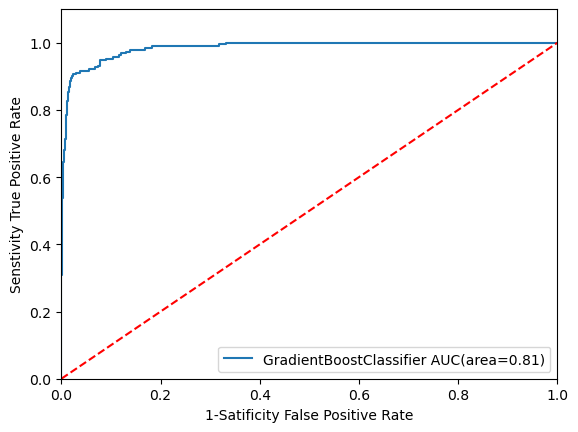

In [29]:
model=[{
    'name':'GradientBoostClassifier',
    'model':GradientBoostingClassifier(min_samples_split=8,max_features='sqrt',max_depth=20,loss='log_loss',learning_rate=0.1,criterion='friedman_mse'),
    'AUC':0.8050
    
}]

for algo in model:
    model=algo['model']
    model.fit(x_train,y_train)

    ##make prediction
    y_pred=model.predict_proba(x_test)

    #only probability of 1
    y_new=y_pred[:,1]

    #calculate False Positive Rate and True Positive Rate 
    fpr,tpr,threshold=roc_curve(y_test,y_new)

    plt.plot(fpr,tpr,label='%s AUC(area=%.2f)'%(algo['name'],algo['AUC']))
plt.plot([0,1],[0,1],'r--')
plt.xlabel('1-Satificity False Positive Rate')
plt.ylabel('Senstivity True Positive Rate')
plt.xlim([0,1.0])
plt.ylim([0,1.1])
plt.legend(loc='lower right')
plt.show




    